In [ ]:
import os
import argparse
import datetime
import random
import math
import cv2
from typing import List, Dict, Tuple, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.optim.lr_scheduler as lr_sched
from torch.utils.data import random_split, DataLoader
#from torch.utils.tensorboard import SummaryWriter
from lib.models.my_arcface import MyArcFace
from lib.utils_functions import seed_worker
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm
'''
special modification for labeling in AIDY data
'''
#from lib.datasets.utils import get_train_and_val_datasets

from lib.datasets.gestalt_matcher_dataset import GestaltMatcherDataset
def __getitem__(self, i, to_augment=True):
    img = cv2.imread(os.path.join(self.imgs_dir, f"{self.targets.iloc[i]['image_id']}{self.img_postfix}.jpg"))
    #target_id = self.lookup_table.index(self.targets.iloc[i]['label'])

    df = pd.read_json("actual_swarm/swarm_study/lookup_table.json")
    df['label']=range(len(df))

    df2 = pd.read_csv("actual_swarm/swarm_study/image_to_class_correspondance.csv")
    df2["AIDY_class"] = df2["cohort"].map(df.set_index(0)['label'])
    target_id = df2[df2["image_number"] == self.targets.iloc[i]["image_id"]]["AIDY_class"].values[0]
    img = self.preprocess(img)
    return img, target_id

GestaltMatcherDataset.__getitem__ = __getitem__
def get_train_and_val_datasets(
        dataset,
        dataset_type,
        version,
        img_size,
        color_channels,
        base_dir,
        train_path,
        val_path,
        lookup_table=None,
        aspect_ratio=False,
        img_postfix='_crop_square'):

    if dataset == 'gmdb':
        dataset_train = GestaltMatcherDataset(
            in_channels=color_channels,
            img_postfix=img_postfix,
            target_size=img_size,
            imgs_dir=os.path.join(base_dir, "GestaltMatcherDB", version, "gmdb_align"),
            target_file_path= train_path, # os.path.join(base_dir, "GestaltMatcherDB", version, "gmdb_metadata",
            #                               f"gmdb_train_images_{version}.csv"),
            lookup_table=lookup_table,
            aspect_ratio=aspect_ratio)

        dataset_val = GestaltMatcherDataset(
            in_channels=color_channels,
            img_postfix=img_postfix,
            target_size=img_size,
            augment=False,
            imgs_dir=os.path.join(base_dir, "GestaltMatcherDB", version, "gmdb_align"),
            target_file_path=val_path, # os.path.join(base_dir, "GestaltMatcherDB", version, "gmdb_metadata",
                                        #   f"gmdb_val_images_{version}.csv"),
            lookup_table=(lookup_table if lookup_table else dataset_train.get_lookup_table()),
            aspect_ratio=aspect_ratio)

    # Unsupported dataset (or typo)
    else:
        print(f"Dataset: {dataset} unknown, exiting.")
        exit()

    print(f"Loaded dataset: {dataset}{'-' if dataset_type else ''}{dataset_type} (version {version}) with image size "
          f"{img_size}x{img_size} in {'gray' if color_channels == 1 else 'RGB'}, while {'' if aspect_ratio else 'not'} "
          f"retaining the aspect ratio.")
    return dataset_train, dataset_val

In [2]:
def parse_args():
    parser = argparse.ArgumentParser(description='PyTorch Modernized GestaltMatcher')

    # Run parameters
    parser.add_argument('--session', default= 1, type=int, dest='session',
                        help='session used to distinguish model tests.')
    parser.add_argument('--batch_size', type=int, default=128, metavar='BN',
                        help='input batch size for training (default: 280)')
    parser.add_argument('--epochs', type=int, default=1, metavar='E',
                        help='number of epochs to train (default: 500)')
    parser.add_argument('--lr', type=float, default=5e-3, metavar='LR',  # lr=1e-3
                        help='learning rate (default: 0.005)')
    parser.add_argument('--seed', type=int, default=11, metavar='S',
                        help='random seed (default: 11)')
    parser.add_argument('--no_cuda', action='store_true', default=False,
                        help='disables CUDA training')
    parser.add_argument('--log_interval', type=int, default=1000,
                        help='how many images (not batches) to wait before logging training status')
    parser.add_argument('--val_interval', type=int, default=10000,
                        help='how many images (not batches) to wait before validation is evaluated (and optimizer is stepped).')
    parser.add_argument('--use_tensorboard', action='store_true', default=False,
                        help='Use tensorboard for logging')

    # Model parameters
    parser.add_argument('--model_type', default='glint360k_r50', dest='model_type',
                        help='model backend to use')
    parser.add_argument('--in_channels', default=3, dest='in_channels', type=int,
                        help='number of color channels of the images used as input (default: 1)')
    parser.add_argument('--img_size', default=112, dest='img_size', type=int,
                        help='input image size of the model (default: 100)')
    parser.add_argument('--unfreeze', action='store_false', default=True, dest='freeze',
                        help='flag to set if you want to unfreeze the base model weights.')

    # Dataset parameters
    parser.add_argument('--dataset', default='gmdb', dest='dataset',
                        help='which dataset to use. (Options: "casia", "gmdb")')
    parser.add_argument('--dataset_type', default='', dest='dataset_type',
                        help='type of the dataset to use, e.g. normal (="") or augmented(="aug") (default="")')
    parser.add_argument('--dataset_version', default='v1.1.0', dest='dataset_version', type=str,
                        help='version of the dataset to use (default="v1.0.3")')
    parser.add_argument('--lookup_table', default='', dest='lookup_table_path',
                        help='lookup table path, use if you want to load path instead of generation a lookup table (default = "")')

    # File locations
    parser.add_argument('--data_dir', default='data', dest='data_dir',
                        help='Location of the data directory (not dataset). (default = home pc)')
    parser.add_argument('--weight_dir', default='saved_models', dest='weight_dir',
                        help='Location of the model weights directory. (default = "saved_models")')

    # running on my local machine means different path types, and num_workers
    parser.add_argument('--local', action='store_true', default=False,
                        help='Running on local machine, fewer num_workers')

    #
    parser.add_argument('--paper_model', default='a', dest='paper_model', type=str,
                        help='Use when reproducing paper models a) r50-mix, or b) r100')

    return parser.parse_known_args()


args, unknown = parse_args()


use_cuda = not args.no_cuda and torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
print(f"Using {'GPU.' if use_cuda else 'CPU, as was explicitly requested, or as GPU is not available.'}")

# Seed everything
np.random.seed(args.seed)
torch.manual_seed(args.seed)
random.seed(args.seed)

# When using GPU we need to set extra seeds
if use_cuda:
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.cuda.manual_seed_all(args.seed)
    torch.cuda.manual_seed(args.seed)
# torch.set_deterministic(True)

# If we want to reproduce paper results, by giving command-line argument `args.paper_model` == 'a' or 'b',
# we replace some other parameters
f_wd = c_wd = lr = c_lr = -1
if args.paper_model == 'a':    # r50 mix
    args.model_type = 'glint360k_r50'
    args.batch_size = 64
    f_wd = 5e-5
    c_wd = 5e-4
    lr = 5e-4
    c_lr = 1e-3
elif args.paper_model == 'b':  # r100
    args.model_type = 'glint360k_r100'
    args.batch_size = 128
    f_wd = 0.
    c_wd = 5e-4
    lr = 1e-3
    c_lr = 1e-3

# Dataset and dataloaders
kwargs = {}
if use_cuda:
    kwargs.update({'num_workers': (0 if args.local else 16), 'pin_memory': True})

dataset_train = dataset_val = None
lookup_table = None
distr = None
args.val_bs = 1

# Create and get the training and validation datasets
dataset_train, dataset_val = get_train_and_val_datasets(args.dataset, args.dataset_type, args.dataset_version,
                                                        args.img_size, args.in_channels, args.data_dir,
                                                        train_path=os.path.join(args.data_dir, "GestaltMatcherDB", 
                                                                                args.dataset_version,"gmdb_metadata",f"gmdb_train_images_{args.dataset_version}.csv"),
                                                        val_path=os.path.join(args.data_dir, "GestaltMatcherDB", 
                                                                                args.dataset_version,"gmdb_metadata",f"gmdb_val_images_{args.dataset_version}.csv"),
                                                        img_postfix='_aligned')
    
        # Get the number of classes from the dataset
args.num_classes = dataset_train.get_num_classes()

# Create dataloaders
train_loader = torch.utils.data.DataLoader(dataset_train, **kwargs, shuffle=True, batch_size=args.batch_size,
                                            worker_init_fn=seed_worker, drop_last=True)
val_loader = torch.utils.data.DataLoader(dataset_val, pin_memory=True, num_workers=12, shuffle=False,
                                            drop_last=False,worker_init_fn=seed_worker,batch_size=args.val_bs)

# Attempt to deal with data imbalance: inverse frequency divided by lowest frequency class (0.5 < class_weight <= 1)
if distr is not None:
    args.ce_weights = (torch.tensor([(sum(distr) / freq) / (sum(distr) / min(distr)) for freq in distr]).float()
                        .to(device)) * 0.5 + 0.5
else:
    args.ce_weights = None

# Set log intervals
args.log_interval = args.log_interval // args.batch_size
args.val_interval = args.val_interval // args.batch_size

use_cuda = not args.no_cuda and torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
print(f"Using {'GPU.' if use_cuda else 'CPU, as was explicitly requested, or as GPU is not available.'}")

# Try and get the dataset distribution and lookup table
try:
    distr = dataset_train.get_distribution()
    print(f"Training dataset size: {sum(distr)}, with {len(distr)} classes and distribution: {distr}")
    print(f"Validation dataset size: {sum(dataset_val.get_distribution())}, "
            f"with distribution: {dataset_val.get_distribution()}")

    lookup_table = dataset_train.get_lookup_table()
except:
    print("An error occurred while getting the dataset distribution and lookup table. Likely the dataset does not "
            "have an implementation for these functions.")
    



Using GPU.
no look up table found
look up table found
Loaded dataset: gmdb (version v1.1.0) with image size 112x112 in RGB, while not retaining the aspect ratio.
Using GPU.
Training dataset size: 7787, with 275 classes and distribution: [361, 241, 224, 171, 168, 147, 144, 132, 131, 119, 111, 96, 93, 93, 84, 75, 75, 74, 73, 72, 71, 69, 67, 63, 63, 62, 61, 56, 54, 54, 54, 51, 51, 50, 49, 47, 47, 47, 45, 45, 44, 44, 43, 42, 42, 42, 42, 42, 42, 40, 39, 39, 38, 38, 37, 36, 36, 36, 35, 35, 35, 34, 33, 33, 31, 31, 31, 31, 30, 30, 30, 30, 29, 29, 29, 28, 28, 28, 28, 27, 27, 27, 27, 27, 26, 26, 26, 26, 26, 26, 26, 25, 25, 24, 24, 24, 24, 24, 24, 23, 23, 23, 23, 23, 23, 22, 22, 22, 21, 21, 21, 21, 21, 21, 21, 21, 21, 20, 20, 20, 20, 19, 19, 19, 19, 19, 19, 19, 18, 18, 18, 18, 18, 18, 18, 17, 17, 17, 17, 17, 17, 17, 17, 17, 16, 16, 16, 16, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 14, 14, 14, 13, 13, 13, 13, 13, 13, 13, 12, 12, 12, 12, 12, 12, 12, 12, 12, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11,

In [ ]:
import pandas as pd
import torch
import os
use_cuda = torch.cuda.is_available() #not args.no_cuda and
device = torch.device("cuda" if use_cuda else "cpu")

if use_cuda:
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

data = os.listdir('data/GestaltMatcherDB/v1.1.0/gmdb_align')
img_meta = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/image_metadata_v1.1.0.tsv', sep='\t')
img_meta = img_meta[['image_id', 'filename', 'internal_syndrome_id']]

training = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_train_images_v1.1.0.csv')
validation = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_val_images_v1.1.0.csv')
test = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_test_images_v1.1.0.csv')

gmdb_data = pd.concat([training, validation, test], ignore_index=True)

GM_AI_label = pd.read_csv('actual_swarm/swarm_study/gmdb_aidy_label_mapping.csv')

In [4]:
disease_over_50 = gmdb_data.groupby('label').filter(lambda x: len(x) > 50)
disease_less_50 = gmdb_data.groupby('label').filter(lambda x: len(x) < 50)

In [5]:
# Preprocessing used for ArcFace input image inference
def preprocess(img, img_size=112, gray=False, flip=False):
    img = cv2.resize(img, (img_size, img_size))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    if gray:
        # desired number of channels is 1, so we convert to gray
        img = A.to_gray(img)
    #else: color

    if flip:
        img = A.hflip(img)
    #else: normal

    # normalize pixel values in range [-1,1]
    img = np.transpose(img, (2, 0, 1))
    img = torch.from_numpy(img).unsqueeze(0).float()
    img.div_(255).sub_(0.5).div_(0.5)
    return img


In [6]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss

# -------------------------------------------------
# Expected Calibration Error (ECE)
# -------------------------------------------------
def compute_ece(probs: np.ndarray, labels: np.ndarray, n_bins: int = 15):
    """
    probs: [N, C] predicted probabilities (softmax)
    labels: [N] true labels
    """
    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    accuracies = (predictions == labels)

    bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    bin_accs, bin_confs, bin_counts = [], [], []

    for i in range(n_bins):
        start, end = bin_boundaries[i], bin_boundaries[i + 1]
        mask = (confidences > start) & (confidences <= end)
        count = np.sum(mask)
        if count > 0:
            acc = np.mean(accuracies[mask])
            conf = np.mean(confidences[mask])
            ece += (count / len(labels)) * abs(acc - conf) 
            '''
            A perfectly calibrated model's confidence should match its accuracy. 
            For example, if a model predicts a 70% chance of rain on 100 different occasions, it should actually rain on approximately 70 of those occasions.
            
            '''
            bin_accs.append(acc)
            bin_confs.append(conf)
            bin_counts.append(count)
        else:
            bin_accs.append(0)
            bin_confs.append(0)
            bin_counts.append(0)

    return ece, bin_accs, bin_confs, bin_counts, bin_boundaries

# -------------------------------------------------
# Brier Score
# -------------------------------------------------
def compute_brier(probs: np.ndarray, labels: np.ndarray):
    n_classes = probs.shape[1]
    y_true = np.zeros_like(probs)
    y_true[np.arange(len(labels)), labels] = 1
    # Flatten for sklearn brier_score_loss (binary only), so compute manually
    return np.mean(np.sum((probs - y_true) ** 2, axis=1))
def plot_reliability_diagram(probs: np.ndarray, labels: np.ndarray, n_bins: int = 15, adaptive: bool = False):
    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    accuracies = (predictions == labels)

    if adaptive:
        # Sort by confidence, split into equal-sized bins
        sorted_idx = np.argsort(confidences)
        bin_sizes = len(confidences) // n_bins
        bin_boundaries = []
        bin_accs, bin_confs = [], []
        for i in range(n_bins):
            start = i * bin_sizes
            end = (i + 1) * bin_sizes if i < n_bins - 1 else len(confidences)
            idx = sorted_idx[start:end]
            bin_accs.append(np.mean(accuracies[idx]))
            bin_confs.append(np.mean(confidences[idx]))
            bin_boundaries.append((confidences[idx[0]], confidences[idx[-1]]))
    else:
        # Fixed bins
        ece, bin_accs, bin_confs, _, bin_boundaries = compute_ece(probs, labels, n_bins)

    plt.figure(figsize=(6,6))
    plt.plot([0,1],[0,1], linestyle="--", color="gray", label="Perfect calibration")
    plt.bar(np.linspace(0+0.5/n_bins, 1-0.5/n_bins, n_bins),
            bin_accs, width=1/n_bins, edgecolor="black", alpha=0.7, label="Empirical")
    plt.scatter(bin_confs, bin_accs, color="red", zorder=5, label="Bin means")
    plt.xlabel("Confidence")
    plt.ylabel("Accuracy")
    plt.title("Reliability Diagram" + (" (Adaptive)" if adaptive else ""))
    plt.legend()
    plt.show()


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")


def wilson_interval(k, n, z=1.96):
    if n == 0:
        return 0, 0

    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denom
    margin = (z * np.sqrt((p*(1-p)/n) + (z**2/(4*n**2)))) / denom

    return center - margin, center + margin


def plot_reliability_diagram(
    probs: np.ndarray,
    labels: np.ndarray,
    n_bins: int = 15,
    adaptive: bool = False,
    figsize=(5,5),
    dpi=300
):

    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    accuracies = (predictions == labels)

    if adaptive:
        sorted_idx = np.argsort(confidences)
        bin_sizes = len(confidences) // n_bins

        bin_accs, bin_confs, bin_counts = [], [], []
        ci_low, ci_high = [], []

        for i in range(n_bins):
            start = i * bin_sizes
            end = (i + 1) * bin_sizes if i < n_bins - 1 else len(confidences)
            idx = sorted_idx[start:end]

            k = np.sum(accuracies[idx])
            n = len(idx)

            acc = k / n
            conf = np.mean(confidences[idx])

            lo, hi = wilson_interval(k, n)

            bin_accs.append(acc)
            bin_confs.append(conf)
            bin_counts.append(n)

            ci_low.append(acc - lo)
            ci_high.append(hi - acc)

        bin_accs = np.array(bin_accs)
        bin_confs = np.array(bin_confs)
        ci_low = np.array(ci_low)
        ci_high = np.array(ci_high)

        bin_centers = bin_confs
        bin_width = 1 / n_bins

    else:
        bins = np.linspace(0, 1, n_bins + 1)
        bin_ids = np.digitize(confidences, bins) - 1

        bin_accs = np.zeros(n_bins)
        bin_confs = np.zeros(n_bins)
        bin_counts = np.zeros(n_bins)
        ci_low = np.zeros(n_bins)
        ci_high = np.zeros(n_bins)

        for b in range(n_bins):

            mask = bin_ids == b
            n = np.sum(mask)

            if n > 0:
                k = np.sum(accuracies[mask])

                acc = k / n

                bin_accs[b] = acc
                bin_confs[b] = np.mean(confidences[mask])
                bin_counts[b] = n

                lo, hi = wilson_interval(k, n)

                ci_low[b] = acc - lo
                ci_high[b] = hi - acc

        bin_centers = (bins[:-1] + bins[1:]) / 2
        bin_width = bins[1] - bins[0]

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)

    ax.plot([0,1], [0,1],
            linestyle="--",
            color="black",
            linewidth=1.5,
            label="Perfect calibration")

    ax.bar(
        bin_centers,
        bin_accs,
        width=bin_width * 0.9,
        color="#4C72B0",
        edgecolor="black",
        linewidth=0.8,
        alpha=0.85,
        label="Empirical accuracy"
    )

    ax.bar(
        bin_centers,
        np.abs(bin_accs - bin_confs),
        bottom=np.minimum(bin_accs, bin_confs),
        width=bin_width * 0.9,
        color="#DD8452",
        alpha=0.6,
        label="Calibration gap"
    )

    # Wilson CI error bars
    ax.errorbar(
        bin_centers,
        bin_accs,
        yerr=[ci_low, ci_high],
        fmt="none",
        ecolor="black",
        elinewidth=1,
        capsize=3,
        zorder=6
    )

    ax.scatter(
        bin_confs,
        bin_accs,
        color="red",
        s=35,
        zorder=7,
        label="Bin mean"
    )

    ax.set_xlabel("Confidence", fontsize=13)
    ax.set_ylabel("Accuracy", fontsize=13)

    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

    ax.set_title(
        "Reliability Diagram" + (" (Adaptive bins)" if adaptive else ""),
        fontsize=14,
        pad=10
    )

    ax.legend(frameon=True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

In [ ]:
def model_prediction_accuracy(model,dataL, dataS, label_data):
    model.eval()
    all_probs=[]
    all_max_id=[]
    actual_id=[]
    dataM = dataS
    with torch.no_grad():
        for idx, img_path in enumerate(tqdm(dataL, desc="Processing images")):
            if len(dataM[dataM['image_id'].isin([int(img_path.split('_')[0])])])>0:
                img = cv2.imread(os.path.join('data/GestaltMatcherDB/v1.1.0/gmdb_align', img_path))

                img_p = preprocess(img).to(device, dtype=torch.float32)

                pred_rep = model(img_p)
                pred, pred_rep = pred_rep
                max_pred, max_idx= torch.topk(pred[:,:275], k=10, dim=-1)
                #pred = pred.squeeze().tolist()
                probs = torch.softmax(pred[:,:275], dim=1).cpu().numpy()
                all_probs.append(probs)
                all_max_id.append(max_idx)
                #ac_id = img_meta.loc[img_meta['filename'] == img_path.split('_')[0]+'.jpg',img_meta.columns[2]].to_list()
                gmdb_id = gmdb_data.loc[gmdb_data['image_id'] == int(img_path.split('_')[0]),gmdb_data.columns[2]].to_list()[0]
                AIDY_id = label_data.loc[label_data['GMDB_label']==gmdb_id,label_data.columns[1]].to_list()[0]
                # AIDY_id = df2.loc[df2['image_number'] == int(img_path.split('_')[0]),df2.columns[2]].values[0]
                actual_id.append(AIDY_id)
                # if len(gmdb_id)>0:
                # if (max_idx.tolist()[0][0]==AIDY_id):
                #     print([img_path,AIDY_id])

    return [all_probs, all_max_id, actual_id]
# model = torch.load('actual_swarm/swarm_study/s1_glint360k_r100_512d_gmdb_aidy__v1.1.0_bs128_size112_channels3_swarm_model_merged.pth',
#                    map_location=device).to(device)

model= torch.load("actual_swarm/swarm_study/s1_glint360k_r100_512d_gmdb_aidy__v1.1.0_bs128_size112_channels3_swarm_model_epoch_49_central.pth",
                  map_location=device).to(device)
all_probs, all_max_id_mod1, actual_id_mod1 =  model_prediction_accuracy(model, data, disease_less_50, GM_AI_label)
all_probs = np.vstack(all_probs)
all_labels = actual_id_mod1 #np.concatenate(actual_id)

n_bins=30
# Compute metrics
ece, bin_accs, bin_confs, bin_counts, bin_boundaries = compute_ece(all_probs, all_labels, n_bins=n_bins)
# brier = compute_brier(all_probs, all_labels)

print(f"ECE = {ece:.4f}")
# print(f"Brier Score = {brier:.4f}")


Processing images: 100%|██████████| 10980/10980 [03:52<00:00, 47.22it/s] 

ECE = 0.0244


In [ ]:
central_model= torch.load("actual_swarm/swarm_study/s1_glint360k_r100_512d_gmdb_aidy__v1.1.0_bs128_size112_channels3_swarm_model_epoch_49_central.pth",
                  map_location=device).to(device)
swarm_model= torch.load("actual_swarm/swarm_study/s1_glint360k_r100_512d_gmdb_aidy__v1.1.0_bs128_size112_channels3_swarm_model_merged.pth",
                  map_location=device).to(device)

all_probs_avg_central, all_max_id_avg_central, actual_id_avg_central =  model_prediction_accuracy(central_model, data, gmdb_data, GM_AI_label)
all_probs_avg_swarm, all_max_id_avg_swarm, actual_id_avg_swarm =  model_prediction_accuracy(swarm_model, data, gmdb_data, GM_AI_label)

all_probs_fre_central, all_max_id_fre_central, actual_id_fre_central =  model_prediction_accuracy(central_model, data, disease_over_50, GM_AI_label)
all_probs_fre_swarm, all_max_id_fre_swarm, actual_id_fre_swarm =  model_prediction_accuracy(swarm_model, data, disease_over_50, GM_AI_label)

all_probs_rare_central, all_max_id_rare_central, actual_id_rare_central =  model_prediction_accuracy(central_model, data, disease_less_50, GM_AI_label)
all_probs_rare_swarm, all_max_id_rare_swarm, actual_id_rare_swarm =  model_prediction_accuracy(swarm_model, data, disease_less_50, GM_AI_label)



all_probs_avg_central, all_probs_avg_swarm = np.vstack(all_probs_avg_central), np.vstack(all_probs_avg_swarm)
all_labels_avg_central, all_labels_avg_swarm = actual_id_avg_central, actual_id_avg_swarm #np.concatenate(actual_id)

all_probs_fre_central, all_probs_fre_swarm = np.vstack(all_probs_fre_central), np.vstack(all_probs_fre_swarm)
all_labels_fre_central, all_labels_fre_swarm = actual_id_fre_central, actual_id_fre_swarm #np.concatenate(actual_id)

all_probs_rare_central, all_probs_rare_swarm = np.vstack(all_probs_rare_central), np.vstack(all_probs_rare_swarm)
all_labels_rare_central, all_labels_rare_swarm = actual_id_rare_central, actual_id_rare_swarm #np.concatenate(actual_id)

Processing images: 100%|██████████| 10980/10980 [03:59<00:00, 45.79it/s] 


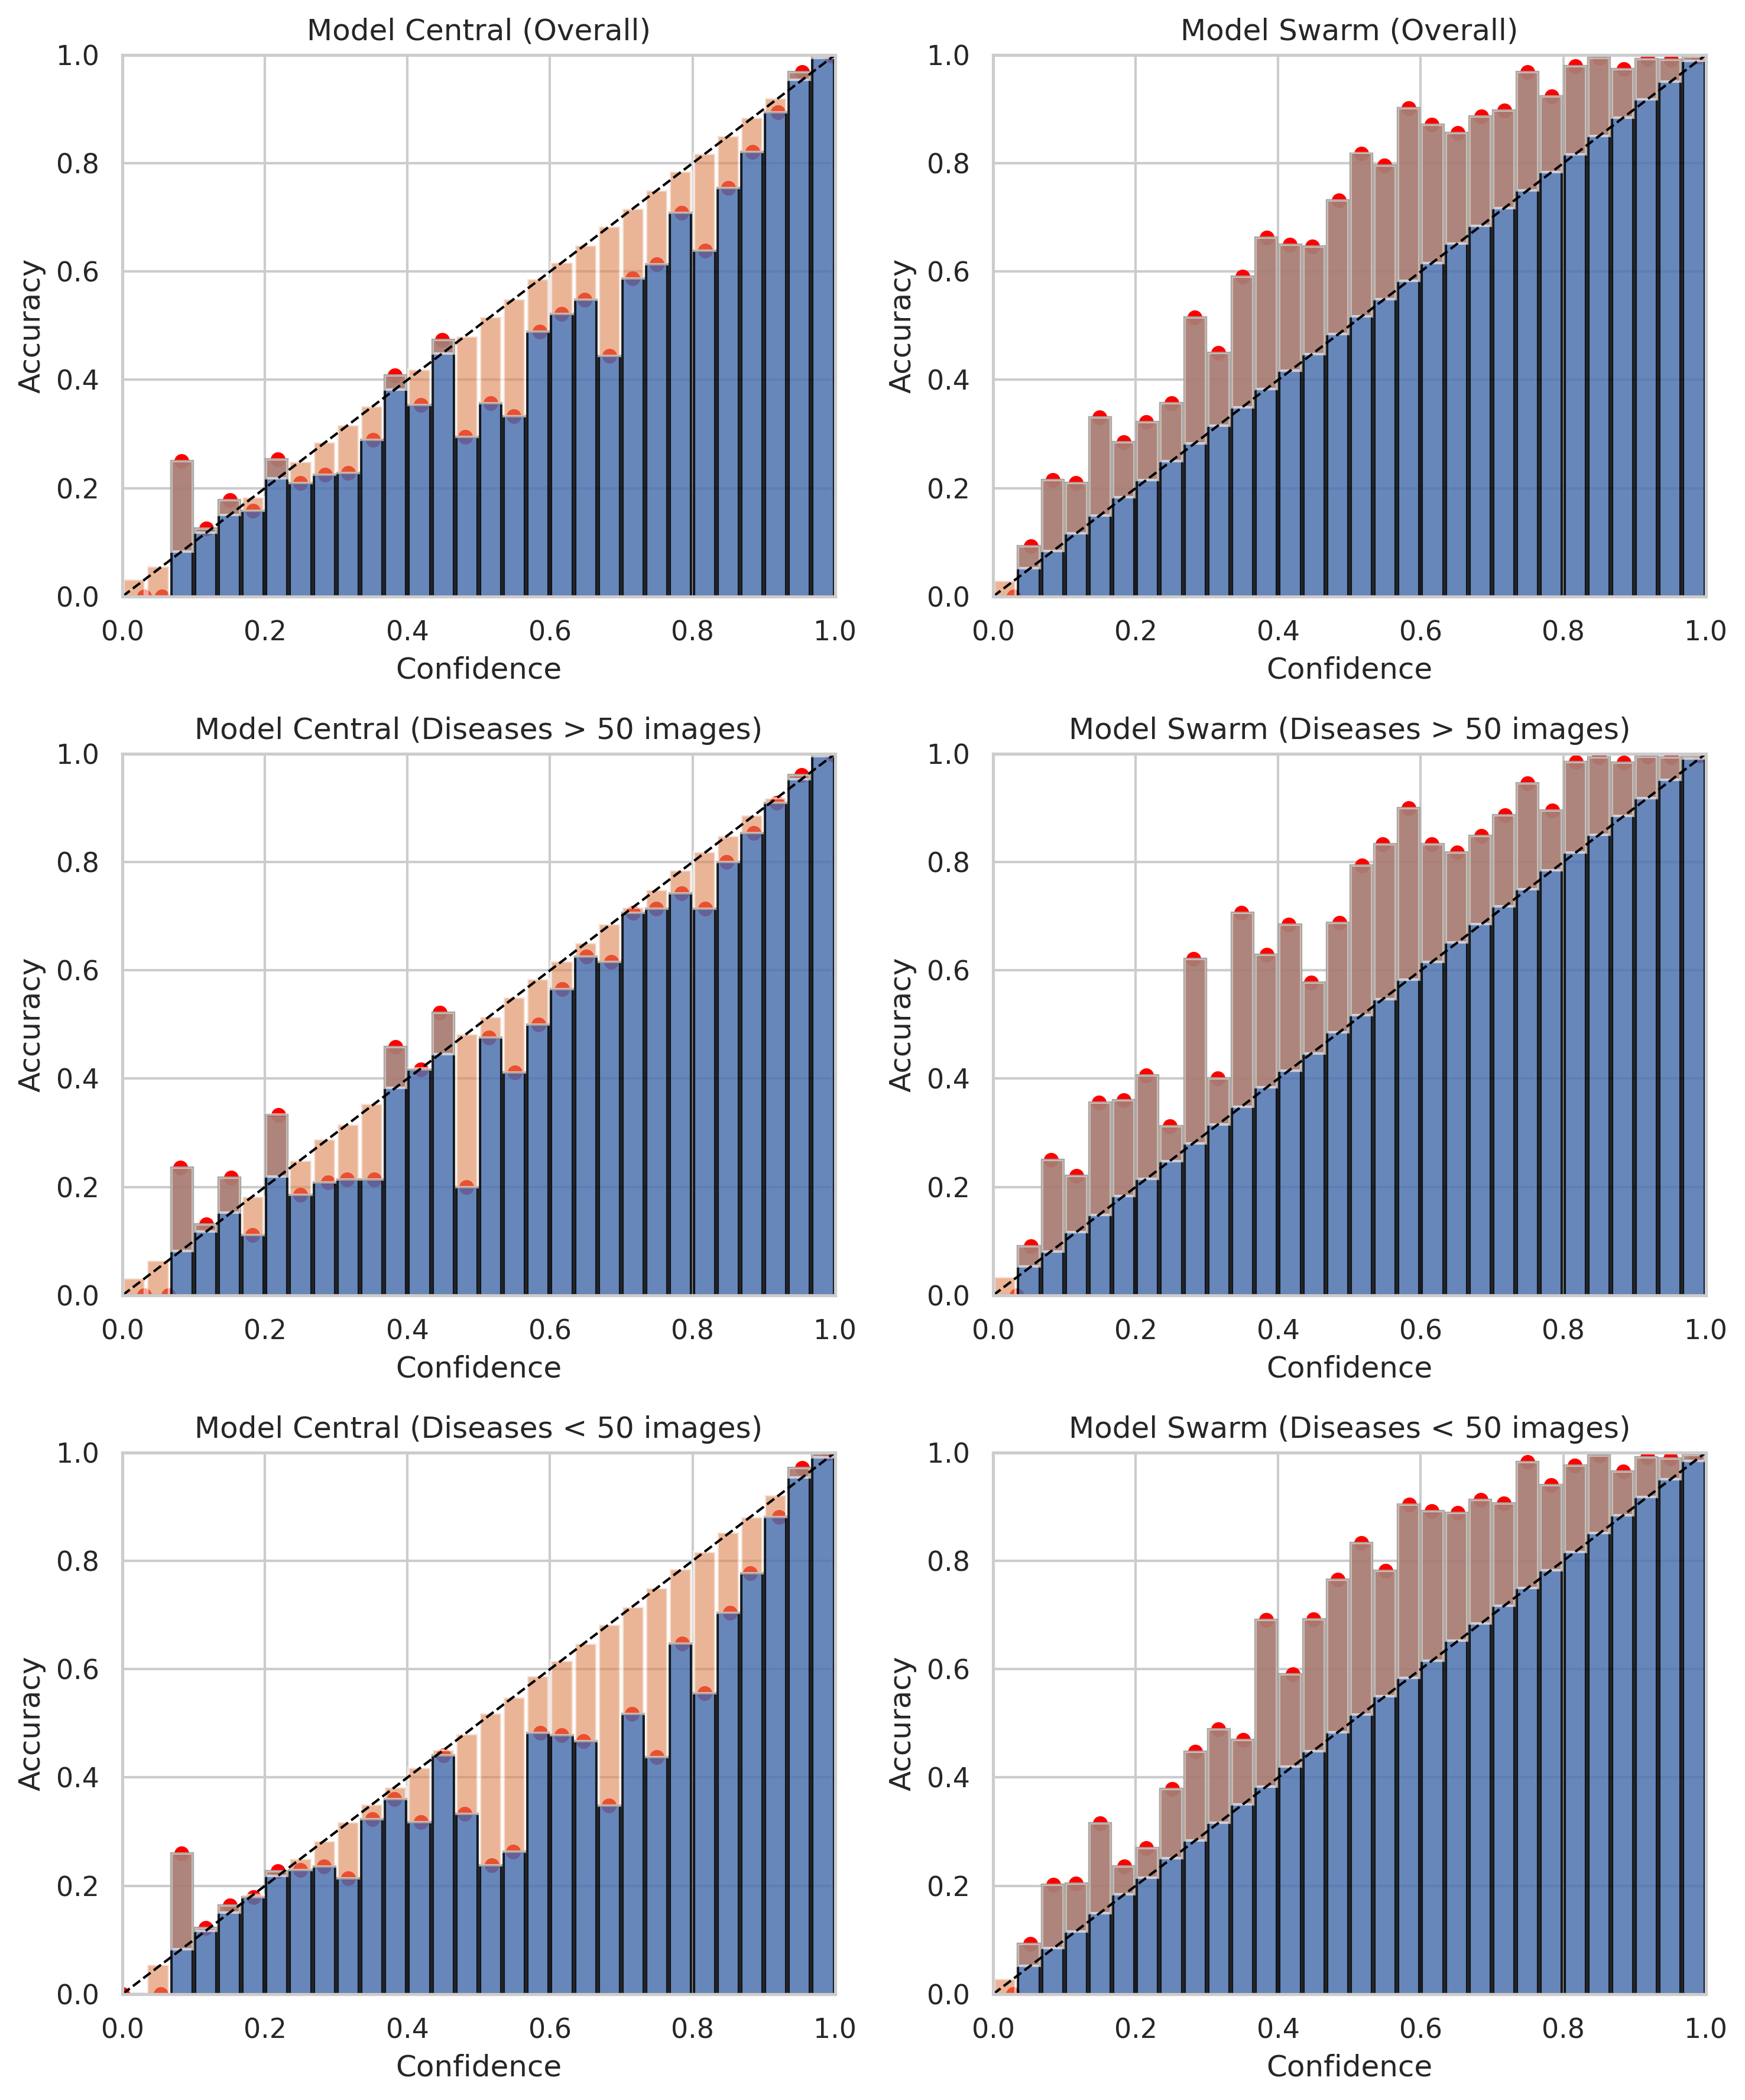

In [11]:
def plot_reliability_diagram(
    probs,
    labels,
    n_bins=30,
    adaptive=False,
    ax=None
):

    if ax is None:
        fig, ax = plt.subplots(figsize=(5,5), dpi=300)

    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    accuracies = (predictions == labels)

    bins = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(confidences, bins) - 1

    bin_accs = np.zeros(n_bins)
    bin_confs = np.zeros(n_bins)

    for b in range(n_bins):
        mask = bin_ids == b
        if np.any(mask):
            bin_accs[b] = np.mean(accuracies[mask])
            bin_confs[b] = np.mean(confidences[mask])

    bin_centers = (bins[:-1] + bins[1:]) / 2
    bin_width = bins[1] - bins[0]

    ax.plot([0,1],[0,1], linestyle="--", color="black", linewidth=1)

    ax.bar(
        bin_centers,
        bin_accs,
        width=bin_width*0.9,
        color="#4C72B0",
        edgecolor="black",
        alpha=0.85
    )

    ax.bar(
        bin_centers,
        np.abs(bin_accs - bin_confs),
        bottom=np.minimum(bin_accs, bin_confs),
        width=bin_width*0.9,
        color="#DD8452",
        alpha=0.6
    )

    ax.scatter(bin_confs, bin_accs, color="red", s=25)

    ax.set_xlim(0,1)
    ax.set_ylim(0,1)
    ax.set_xlabel("Confidence")
    ax.set_ylabel("Accuracy")

fig, axes = plt.subplots(3, 2, figsize=(10, 12), dpi=300)

axes = axes.flatten()

probs_list = [all_probs_avg_central,all_probs_avg_swarm,
              all_probs_fre_central,all_probs_fre_swarm,
              all_probs_rare_central,all_probs_rare_swarm]

labels_list = [all_labels_avg_central,all_labels_avg_swarm,
               all_labels_fre_central,all_labels_fre_swarm,
               all_labels_rare_central,all_labels_rare_swarm]
titles = [
    "Model Central (Overall)",
    "Model Swarm (Overall)",
    "Model Central (Diseases > 50 images)",
    "Model Swarm (Diseases > 50 images)",
    "Model Central (Diseases < 50 images)",
    "Model Swarm (Diseases < 50 images)"
]

for i in range(6):
    plot_reliability_diagram(probs_list[i], labels_list[i], ax=axes[i])
    axes[i].set_title(titles[i])

plt.tight_layout()
plt.show()

AttributeError: 'Figure' object has no attribute 'supxlabel'

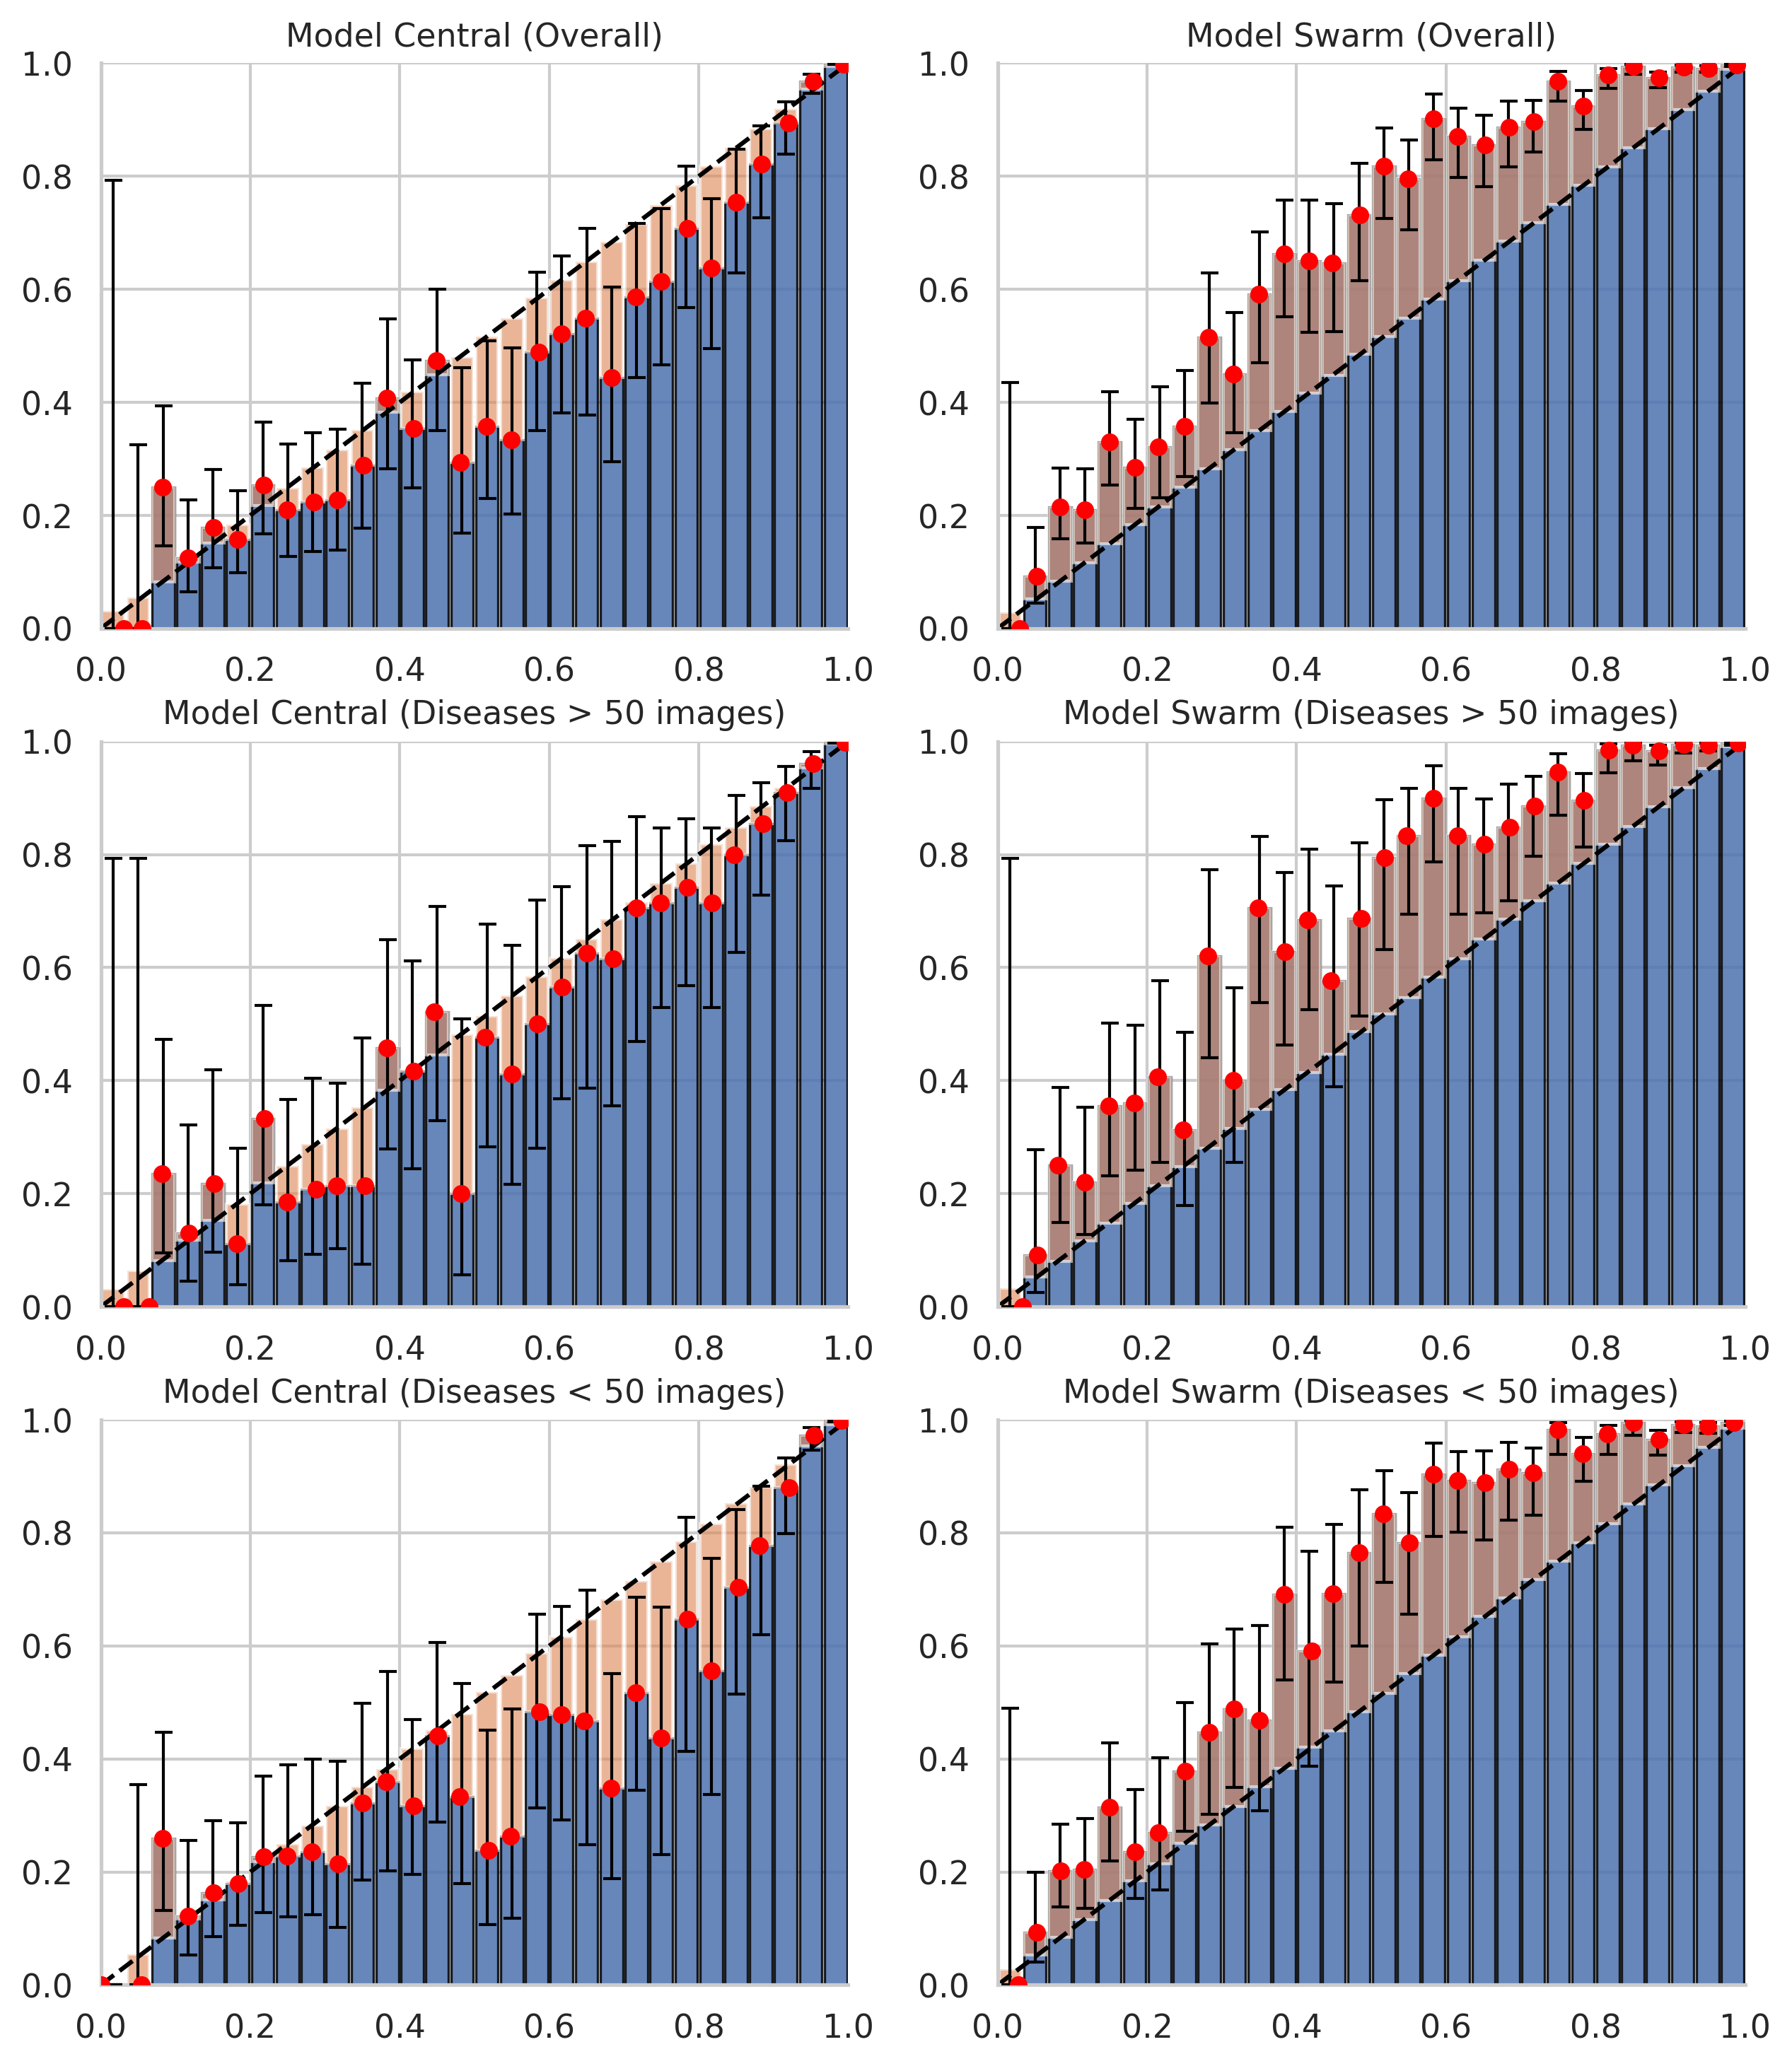

In [12]:
def plot_reliability_diagram(
    probs: np.ndarray,
    labels: np.ndarray,
    n_bins: int = 30,
    adaptive: bool = False,
    ax=None   # <-- add this
):

    if ax is None:
        fig, ax = plt.subplots(figsize=(5,5), dpi=300)

    confidences = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    accuracies = (predictions == labels)

    if adaptive:
        sorted_idx = np.argsort(confidences)
        bin_sizes = len(confidences) // n_bins

        bin_accs, bin_confs, bin_counts = [], [], []
        ci_low, ci_high = [], []

        for i in range(n_bins):
            start = i * bin_sizes
            end = (i + 1) * bin_sizes if i < n_bins - 1 else len(confidences)
            idx = sorted_idx[start:end]

            k = np.sum(accuracies[idx])
            n = len(idx)

            acc = k / n
            conf = np.mean(confidences[idx])

            lo, hi = wilson_interval(k, n)

            bin_accs.append(acc)
            bin_confs.append(conf)
            bin_counts.append(n)

            ci_low.append(acc - lo)
            ci_high.append(hi - acc)

        bin_accs = np.array(bin_accs)
        bin_confs = np.array(bin_confs)
        ci_low = np.array(ci_low)
        ci_high = np.array(ci_high)

        bin_centers = bin_confs
        bin_width = 1 / n_bins

    else:
        bins = np.linspace(0, 1, n_bins + 1)
        bin_ids = np.digitize(confidences, bins) - 1

        bin_accs = np.zeros(n_bins)
        bin_confs = np.zeros(n_bins)
        ci_low = np.zeros(n_bins)
        ci_high = np.zeros(n_bins)

        for b in range(n_bins):
            mask = bin_ids == b
            n = np.sum(mask)

            if n > 0:
                k = np.sum(accuracies[mask])
                acc = k / n

                bin_accs[b] = acc
                bin_confs[b] = np.mean(confidences[mask])

                lo, hi = wilson_interval(k, n)

                ci_low[b] = acc - lo
                ci_high[b] = hi - acc

        bin_centers = (bins[:-1] + bins[1:]) / 2
        bin_width = bins[1] - bins[0]

    # -----------------------
    # Plot on given axis
    # -----------------------

    ax.plot([0,1], [0,1],
            linestyle="--",
            color="black",
            linewidth=1.5)

    ax.bar(
        bin_centers,
        bin_accs,
        width=bin_width * 0.9,
        color="#4C72B0",
        edgecolor="black",
        linewidth=0.8,
        alpha=0.85
    )

    ax.bar(
        bin_centers,
        np.abs(bin_accs - bin_confs),
        bottom=np.minimum(bin_accs, bin_confs),
        width=bin_width * 0.9,
        color="#DD8452",
        alpha=0.6
    )

    ax.errorbar(
        bin_centers,
        bin_accs,
        yerr=[ci_low, ci_high],
        fmt="none",
        ecolor="black",
        elinewidth=1,
        capsize=3,
        zorder=6
    )

    ax.scatter(
        bin_confs,
        bin_accs,
        color="red",
        s=25,
        zorder=7
    )

    ax.set_xlim(0,1)
    ax.set_ylim(0,1)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)



fig, axes = plt.subplots(3, 2, figsize=(10, 12), dpi=300)
axes = axes.flatten()

for i in range(6):
    plot_reliability_diagram(
        probs_list[i],
        labels_list[i],
        ax=axes[i]   # <-- important
    )
    axes[i].set_title(titles[i], fontsize=11)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

# Add shared labels (cleaner)
fig.supxlabel("Confidence")
fig.supylabel("Accuracy")

plt.tight_layout()
plt.show()